# LDR Light Sensor Analysis (600 Samples)

**Wireless Sensor Networks Lab 1**  
**Purpose:** Examine the 600 recorded LDR readings, calculate descriptive statistics, and visualise how the readings change across the sample sequence.

This notebook focuses only on the `light` column in the updated combined sensor dataset. The readings are **normalised values between 0 and 1**; they are not measurements in lux.

## 1. Load the dataset

The notebook is saved in the repository's `python/` folder. The dataset should be saved in `data/raw/` as `WSN_Lab1_Combined_Updated_LDR.csv`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the dataset relative to this notebook/repository.
possible_paths = [
    Path("../data/raw/WSN_Lab1_Combined_Updated_LDR.csv"),
    Path("data/raw/WSN_Lab1_Combined_Updated_LDR.csv"),
    Path("WSN_Lab1_Combined_Updated_LDR.csv"),
]

CSV_PATH = next((p for p in possible_paths if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Place WSN_Lab1_Combined_Updated_LDR.csv "
        "inside the repository's data/raw/ folder."
    )

data = pd.read_csv(CSV_PATH)
print("Dataset location:", CSV_PATH)
print("Dataset shape:", data.shape)
data.head()


Dataset location: ../data/raw/WSN_Lab1_Combined_Updated_LDR.csv
Dataset shape: (600, 17)


,timestamp,temp,humidity,light,motion,temp_cal,temp_filt,delta_temp,status,valid,dht_fresh,event,ref_temp,pc_time,t_s,clock,x
0,604.02,30.5,54.4,0.9144,0,32.61,32.61,0.0,NORMAL,1,1,0,32.43,17:15:37,0.0,1900-01-01 17:15:37,1900-01-01 17:15:37
1,605.02,30.5,54.4,0.9125,0,32.61,32.61,NaN,NORMAL,1,0,0,32.42,17:15:38,1.0,1900-01-01 17:15:38,1900-01-01 17:15:38
2,606.02,30.5,54.4,0.9132,0,32.61,32.61,0.0,NORMAL,1,1,0,32.35,17:15:39,2.0,1900-01-01 17:15:39,1900-01-01 17:15:39
3,607.02,30.5,54.4,0.9125,0,32.61,32.61,NaN,NORMAL,1,0,0,32.44,17:15:40,3.0,1900-01-01 17:15:40,1900-01-01 17:15:40
4,608.02,30.5,54.4,0.9127,0,32.61,32.61,0.0,NORMAL,1,1,0,32.41,17:15:41,4.0,1900-01-01 17:15:41,1900-01-01 17:15:41


## 2. Validate and select the LDR readings

We check that the `light` column exists, convert it to numeric values, and count any missing readings before analysis.

In [2]:
if "light" not in data.columns:
    raise KeyError("The dataset does not contain a 'light' column.")

ldr = pd.to_numeric(data["light"], errors="coerce")
print("Total samples:", len(ldr))
print("Valid LDR readings:", ldr.notna().sum())
print("Missing/invalid LDR readings:", ldr.isna().sum())

# Keep the original row order and use sample number as the horizontal axis.
valid = ldr.notna()
sample_number = np.arange(1, len(ldr) + 1)


Total samples: 600
Valid LDR readings: 600
Missing/invalid LDR readings: 0


## 3. Descriptive statistics

The following statistics summarise the valid normalised LDR readings.

In [3]:
ldr_stats = ldr.describe().rename({
    "count": "Count",
    "mean": "Mean",
    "std": "Standard deviation",
    "min": "Minimum",
    "25%": "25th percentile",
    "50%": "Median",
    "75%": "75th percentile",
    "max": "Maximum"
})
display(ldr_stats.to_frame(name="LDR reading").round(4))


,LDR reading
Count,600.0000
Mean,0.6275
Standard deviation,0.2900
Minimum,0.1358
25th percentile,0.2701
Median,0.6276
75th percentile,0.9108
Maximum,0.9274


## 4. Plot LDR readings across all 600 samples

Each point represents one row in the dataset. Sample number is used on the x-axis because the corrected LDR values are aligned to the 600 records by row order. The y-axis is a normalised reading from 0 to 1, not a lux measurement.

The code saves the graph in the repository's `figures/` folder using the filename `04_LDR_light_vs_time.png`, matching the filename used for the updated graph on GitHub.

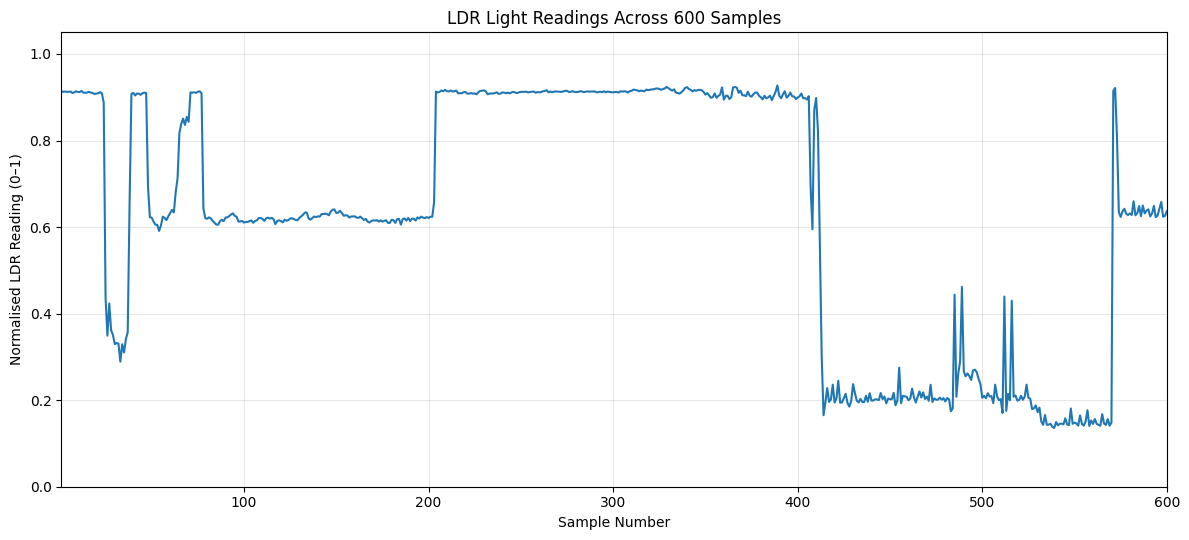

In [4]:
# Save the corrected graph using the same filename uploaded to GitHub.
from pathlib import Path

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)
graph_path = figures_dir / "04_LDR_light_vs_time.png"

plt.figure(figsize=(12, 5.5))
plt.plot(sample_number[valid], ldr[valid], linewidth=1.5)
plt.title("Updated LDR Light Readings")
plt.xlabel("Sample number")
plt.ylabel("Normalised LDR reading (0 to 1)")
plt.xlim(0, len(ldr))
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
print("Graph saved to:", graph_path.resolve())
plt.show()


## 5. Interpretation

- The dataset contains **600 samples**, and all 600 rows have valid LDR readings.
- The readings range from **0.1358** to **0.9274**.
- The mean reading is approximately **0.6275**, and the standard deviation is approximately **0.2900**.
- The plot shows several clear changes in the LDR signal: high readings in parts of the early and middle samples, a substantial decrease around samples 415 onward, and a rise again near the final samples.
- These changes indicate variation in the sensor's recorded light level during acquisition. Whether a higher normalised value means brighter or darker conditions depends on the LDR voltage-divider wiring and calibration. The normalised values should not be described as lux without a separate calibration.

## 6. Conclusion

The LDR analysis successfully summarises and visualises all 600 recorded readings. The graph makes changes and transitions in the sensor signal easy to identify. The analysis can be reproduced by running the notebook from the repository while keeping the CSV in `data/raw/`.